In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df =pd.read_csv(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Zomato project\data\zomato.csv",encoding='latin-1')

print(f'Raw shape :{df.shape}')

Raw shape :(9551, 21)


In [3]:
df=df[df['Country Code']==1].copy()
print(f'After filtering for India shape :{df.shape}')

After filtering for India shape :(8652, 21)


In [4]:
df = df[df['Aggregate rating'] > 0].copy()
print(f'After filtering for Aggregate rating > 0 shape :{df.shape}')

After filtering for Aggregate rating > 0 shape :(6513, 21)


In [5]:
print(df.columns.tolist())
print(df['City'].value_counts().head(5))

['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']
City
New Delhi    4048
Gurgaon       890
Noida         696
Faridabad     151
Ghaziabad      23
Name: count, dtype: int64


# Q1 - Which city has the most restaurants on Zomato?

The Question: 
Among all Indian cities in the dataset, which ones have the highest number of restaurants listed on Zomato?

Why analysts ask this: Market penetration. A food delivery company wants to know where their platform is strongest and where there is room to grow. If Mumbai has 4,000 listings and Jaipur has 200, that tells you where to focus expansion efforts. This is the first question any product analyst at Zomato would ask.

           City  Count
0     New Delhi   4048
1       Gurgaon    890
2         Noida    696
3     Faridabad    151
4     Ghaziabad     23
5      Guwahati     21
6       Lucknow     21
7  Bhubaneshwar     21
8     Ahmedabad     21
9      Amritsar     21


C:\Users\Pushk\AppData\Local\Temp\ipykernel_71084\3734517380.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='City',y='Count',data=top_cities,palette='Reds_d')


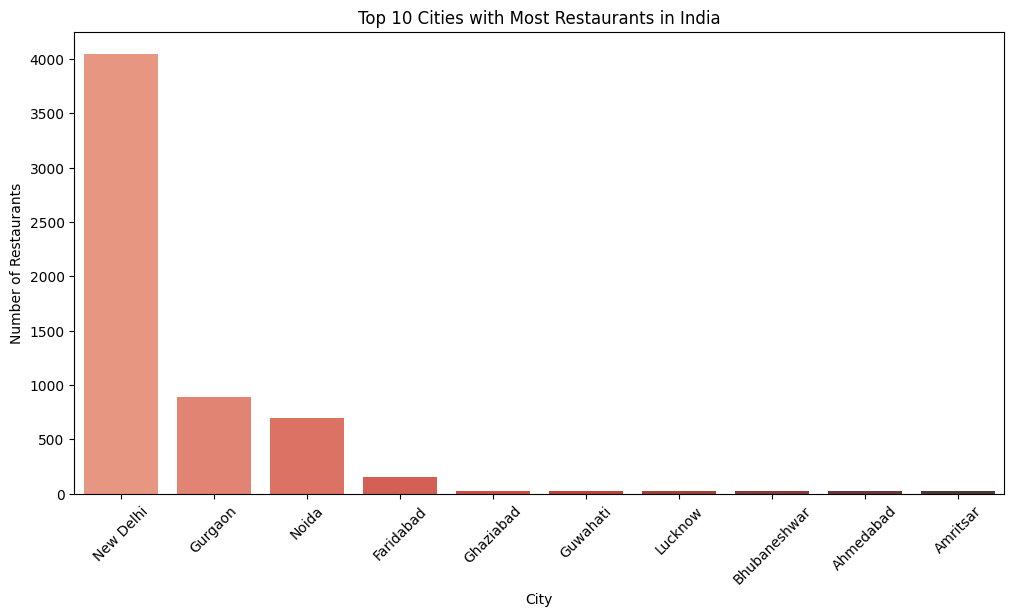

In [6]:
city_counts =df['City'].value_counts().reset_index()
city_counts.columns = ['City','Count']

print(city_counts.head(10))

top_cities = city_counts.head(10)
plt.figure(figsize=(12,6))
sns.barplot(x='City',y='Count',data=top_cities,palette='Reds_d')
plt.title('Top 10 Cities with Most Restaurants in India')
plt.xlabel('City')
plt.ylabel('Number of Restaurants')
plt.xticks(rotation=45)
plt.savefig(r'C:\Users\Pushk\Desktop\COURSES\PROJECTS\Zomato project\visuals\restaurants_by_city.png',bbox_inches ='tight')
plt.show()

# Q2 - What are the most popular cuisines?

The Question: What types of food do the most restaurants in India serve?

Why analysts ask this: This is supply-side analysis. If 60% of restaurants serve North Indian food, that tells you what Indian consumers eat most - and what a new restaurant should probably offer to get customers. For Zomato, it also shows which cuisine categories need more restaurant partners.

         Cuisine  Count
0   North Indian   3003
1        Chinese   2139
2      Fast Food   1540
3        Mughlai    791
4    Continental    687
5        Italian    644
6           Cafe    559
7         Bakery    517
8       Desserts    487
9   South Indian    480
10   Street Food    395
11         Pizza    260
12        Mithai    251
13      American    216
14          Thai    200


C:\Users\Pushk\AppData\Local\Temp\ipykernel_71084\461453369.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Count',y='Cuisine',data=top_cuisines, palette='Oranges_d')


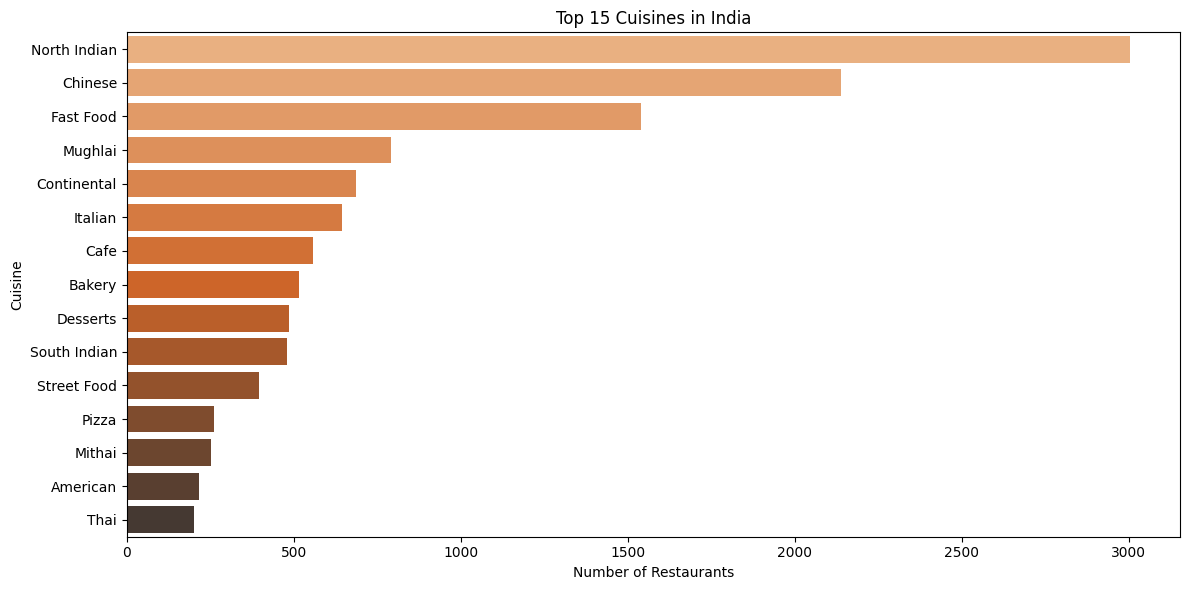

In [7]:
cuisine_series =df['Cuisines'].dropna().str.split(',').explode()
cuisine_series=cuisine_series.str.strip()

cuisine_counts = cuisine_series.value_counts().reset_index()
cuisine_counts.columns = ['Cuisine','Count']

print(cuisine_counts.head(15))

top_cuisines = cuisine_counts.head(15)
plt.figure(figsize=(12,6))
sns.barplot(x='Count',y='Cuisine',data=top_cuisines, palette='Oranges_d')
plt.title('Top 15 Cuisines in India')
plt.xlabel('Number of Restaurants')
plt.tight_layout()
plt.savefig(r'C:\Users\Pushk\Desktop\COURSES\PROJECTS\Zomato project\visuals\top_cuisines.png',bbox_inches ='tight')
plt.show()


# Q3 - Which cuisines have the highest average ratings?

The Question: Among the common cuisines, which ones get the best average customer ratings?

Why analysts ask this: Popularity (Q2) and quality (Q3) are different things. A cuisine can be everywhere but rated poorly. An analyst separates these two - it helps Zomato recommend high-quality cuisine categories to new users, and helps restaurant owners understand which food types customers are happiest with.

          Cuisine  Average Rating
18  Mediterranean            3.98
10       European            3.91
1           Asian            3.85
19        Mexican            3.83
26        Seafood            3.78
15        Italian            3.71
8     Continental            3.70
29           Thai            3.69
16       Japanese            3.66
6            Cafe            3.63


C:\Users\Pushk\AppData\Local\Temp\ipykernel_71084\2701759325.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Average Rating',y='Cuisine',data=cuisine_ratings,palette='Greens_d')


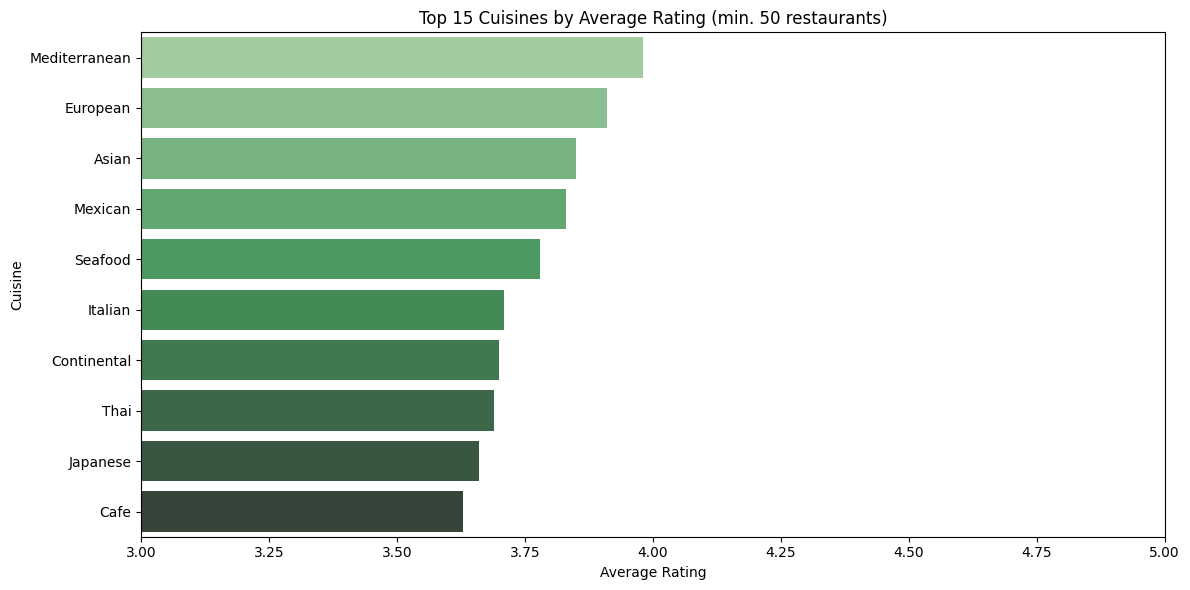

In [8]:
df_exploded = df[['Cuisines','Aggregate rating']].copy()
df_exploded['Cuisines'] = df_exploded['Cuisines'].str.split(',')
df_exploded = df_exploded.explode('Cuisines')
df_exploded['Cuisines'] = df_exploded['Cuisines'].str.strip()

cuisine_popularity = df_exploded['Cuisines'].value_counts()
common_cuisines = cuisine_popularity[cuisine_popularity > 50].index
df_common = df_exploded[df_exploded['Cuisines'].isin(common_cuisines)]

cuisine_ratings = df_common.groupby('Cuisines')['Aggregate rating'].mean().reset_index()
cuisine_ratings.columns = ['Cuisine', 'Average Rating']
cuisine_ratings = cuisine_ratings.sort_values(by='Average Rating', ascending=False).head(10)
cuisine_ratings['Average Rating'] = cuisine_ratings['Average Rating'].round(2)

print(cuisine_ratings)

plt.figure(figsize =(12,6))
sns.barplot(x='Average Rating',y='Cuisine',data=cuisine_ratings,palette='Greens_d')
plt.title('Top 15 Cuisines by Average Rating (min. 50 restaurants)')
plt.xlabel('Average Rating')
plt.xlim(3, 5)  # ratings are between 1-5, zoom in to see differences clearly
plt.tight_layout()
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Zomato Project\visuals\cuisine_avg_ratings.png", bbox_inches='tight')
plt.show()

# Q4 - Does price range affect customer ratings?

The Question: Restaurants are split into 4 price ranges (1=cheap, 4=expensive). Do pricier restaurants get better ratings from customers?

Why analysts ask this: This is a classic assumption people make - expensive means better. An analyst tests whether that assumption is actually true in the data. If cheap restaurants rate just as highly as expensive ones, it tells Zomato not to push premium listings as the default recommendation.

     Price Label  Average Rating
0       1-Budget            3.20
1   2 - Moderate            3.31
2  3 - Expensive            3.68
3     4 - Luxury            3.73
Price Label
1-Budget         2596
2 - Moderate     2462
3 - Expensive    1078
4 - Luxury        377
Name: count, dtype: int64


C:\Users\Pushk\AppData\Local\Temp\ipykernel_71084\2874249919.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df , x='Price Label',y='Aggregate rating',order =['1-Budget','2 - Moderate','3 - Expensive','4 - Luxury'],palette='Blues')


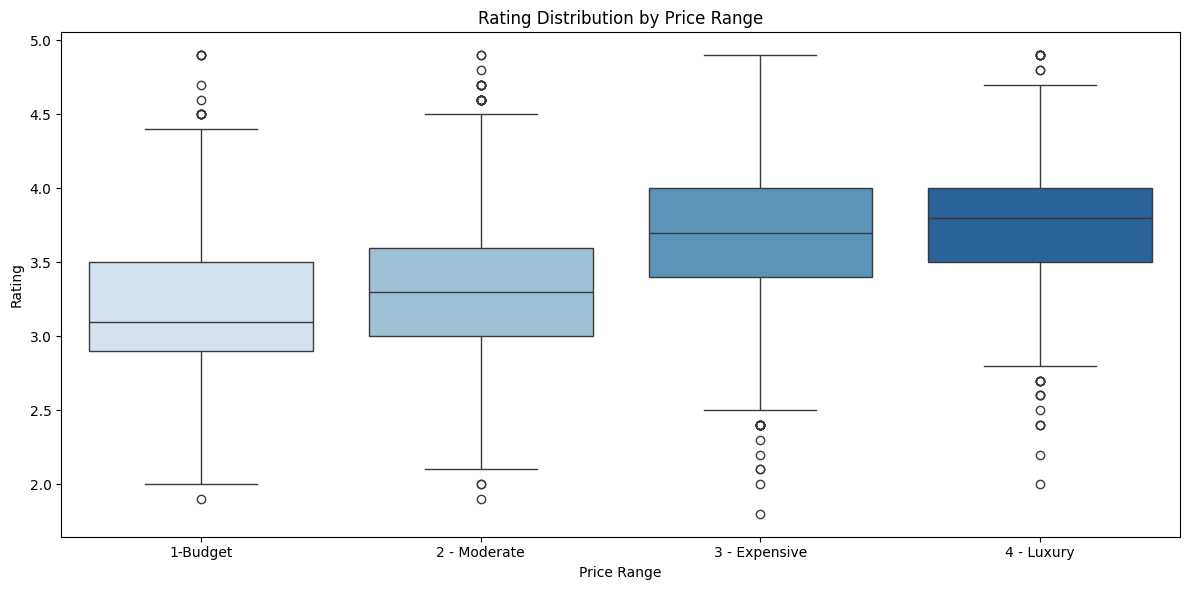

In [9]:
price_labels = {1: '1-Budget', 2: '2 - Moderate', 3: '3 - Expensive', 4: '4 - Luxury'}
df['Price Label']=df['Price range'].map(price_labels)

price_ratings =  df.groupby('Price Label')['Aggregate rating'].mean().reset_index()
price_ratings.columns = ['Price Label', 'Average Rating']
price_ratings['Average Rating'] = price_ratings['Average Rating'].round(2)

print(price_ratings)
print(df['Price Label'].value_counts())

plt.figure(figsize=(12,6))
sns.boxplot(data=df , x='Price Label',y='Aggregate rating',order =['1-Budget','2 - Moderate','3 - Expensive','4 - Luxury'],palette='Blues')
plt.title('Rating Distribution by Price Range')
plt.xlabel('Price Range')
plt.ylabel('Rating')
plt.tight_layout()
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Zomato Project\visuals\price_vs_rating.png", bbox_inches='tight')
plt.show()

### Q5 - What percentage of restaurants offer online delivery?

  Has Online Delivery  Count
0                  No   4186
1                 Yes   2327

Restaurants with online delivery: 2327 (35.7%)


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Pushk\\Desktop\\COURSES\\PROJECTS\\Zomato Analysis\\visuals\\online_delivery_share.png'

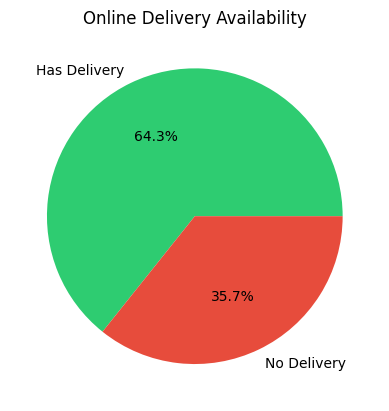

In [10]:
delivery_counts = df['Has Online delivery'].value_counts().reset_index()
delivery_counts.columns = ['Has Online Delivery', 'Count']
print(delivery_counts)

total = len(df)
delivery_yes = len(df[df['Has Online delivery'] == 'Yes'])
print(f'\nRestaurants with online delivery: {delivery_yes} ({delivery_yes/total*100:.1f}%)')

df['Has Online delivery'].value_counts().plot(
    kind='pie', autopct='%1.1f%%',
    colors=['#2ecc71', '#e74c3c'],
    labels=['Has Delivery', 'No Delivery']
)
plt.title('Online Delivery Availability')
plt.ylabel('')
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Zomato Analysis\visuals\online_delivery_share.png", bbox_inches='tight')
plt.show()

delivery_ratings = df.groupby('Has Online delivery')['Aggregate rating'].mean().reset_index()
delivery_ratings.columns = ['Has Delivery', 'Avg Rating']
delivery_ratings['Avg Rating'] = delivery_ratings['Avg Rating'].round(2)
print('\nAverage rating by delivery availability:')
print(delivery_ratings)

### Q6 - Do restaurants with table booking get rated higher?

In [ ]:
booking_ratings = df.groupby('Has Table booking')['Aggregate rating'].mean().reset_index()
booking_ratings.columns = ['Has Table Booking', 'Avg Rating']
booking_ratings['Avg Rating'] = booking_ratings['Avg Rating'].round(2)
print(booking_ratings)

booking_counts = df['Has Table booking'].value_counts()
print('\nRestaurant counts:')
print(booking_counts)

sns.barplot(data=booking_ratings, x='Has Table Booking', y='Avg Rating',
            palette={'Yes': '#2ecc71', 'No': '#e74c3c'})
plt.title('Average Rating: Table Booking vs No Table Booking')
plt.ylabel('Average Rating')
plt.ylim(0, 5)
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Zomato Analysis\visuals\table_booking_vs_rating.png", bbox_inches='tight')
plt.show()

### Q7 - What is the distribution of restaurant ratings?

In [ ]:
rating_dist = df['Rating text'].value_counts().reset_index()
rating_dist.columns = ['Rating Category', 'Count']
print(rating_dist)

rating_order = ['Poor', 'Average', 'Good', 'Very Good', 'Excellent']
rating_dist = rating_dist[rating_dist['Rating Category'].isin(rating_order)]
rating_dist['Rating Category'] = pd.Categorical(rating_dist['Rating Category'],
                                                  categories=rating_order, ordered=True)
rating_dist = rating_dist.sort_values('Rating Category')


colors = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#27ae60']
plt.figure(figsize=(10, 5))
plt.bar(rating_dist['Rating Category'], rating_dist['Count'], color=colors)
plt.title('Distribution of Restaurant Rating Categories')
plt.xlabel('Rating Category')
plt.ylabel('Number of Restaurants')
plt.tight_layout()
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Zomato Analysis\visuals\rating_distribution.png", bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(df['Aggregate rating'], bins=20, color='steelblue', edgecolor='white')
plt.title('Distribution of Aggregate Ratings')
plt.xlabel('Rating (out of 5)')
plt.ylabel('Number of Restaurants')
plt.tight_layout()
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Zomato Analysis\visuals\rating_histogram.png", bbox_inches='tight')
plt.show()

### Q8 - Do more votes mean higher ratings?

In [ ]:
votes_cap = df['Votes'].quantile(0.99)
df_filtered = df[df['Votes'] <= votes_cap]

# Scatter plot: votes on x, rating on y
plt.figure(figsize=(10, 6))
plt.scatter(df_filtered['Votes'], df_filtered['Aggregate rating'],
            alpha=0.2, color='steelblue', s=10)
plt.title('Votes vs Rating (each dot = one restaurant)')
plt.xlabel('Number of Votes (Reviews)')
plt.ylabel('Aggregate Rating')
plt.axhline(df['Aggregate rating'].mean(), color='red', linestyle='--',
            linewidth=0.8, label=f'Avg Rating: {df["Aggregate rating"].mean():.2f}')
plt.legend()
plt.tight_layout()
plt.savefig(r"C:\Users\Pushk\Desktop\COURSES\PROJECTS\Zomato Analysis\visuals\votes_vs_rating.png", bbox_inches='tight')
plt.show()

# Correlation
corr = df['Votes'].corr(df['Aggregate rating'])
print(f'Correlation between Votes and Rating: {corr:.2f}')